# Spotify Listening History — A Deeper Look

Spotify Wrapped gives you a few headline numbers once a year: your top
artist, your top song, a genre or two. It's fun, but deliberately
shallow — a handful of cherry-picked stats designed to be shareable, not
a real picture of how someone actually listens to music over time.

This notebook is an attempt at the real picture: **7.5+ years of my own
Spotify Extended Streaming History**, analyzed end to end — total
listening volume, how taste has shifted year by year, when and how long
listening actually happens, and a genre breakdown that goes well beyond
"here's your top genre." Genre isn't in Spotify's export at all, so this
project also had to build its own genre-resolution pipeline from scratch
(more on that in the methodology section near the end).

This notebook is **self-contained**: every number and chart below is
computed directly from the underlying cached data, with the code that
produces it visible in the cell above each result — nothing here is
copy-pasted from a separate write-up. It's a companion to (not a summary
of) this project's `REPORT.md` and `README.md`, which cover overlapping
ground with additional narrative detail and a couple of real debugging
stories from building the pipeline.

**A note on scope, up front**: partway through this notebook, one genre
turns out to account for a large share of the listening history. That
finding shows up because the data shows it, in the genre breakdown a few
cells down — computed the same way it would be for any other genre, with
no assumption going in about which one would come out on top.

## 1. Data overview

This project's pipeline (see `README.md`) already parsed Spotify's raw
export into two cleaned parquet files, which this notebook loads
directly:
- `streaming_history_clean.parquet` — every play **excluding** plays
  under 30 seconds (the standard threshold for stripping out accidental
  taps and near-instant skips). Almost everything below uses this.
- `streaming_history_full.parquet` — the same plays, **unfiltered**. Used
  specifically where the short-play filter would remove the exact signal
  being measured (skip behavior, daily listening consistency).

Genre data isn't in Spotify's export — it was resolved separately via
MusicBrainz's public API (a story in itself; see the methodology section)
and cached to `data/artist_genres.json`. This notebook loads that
**cache**, not a live API — the crawl took several hours at MusicBrainz's
~1 request/second limit and doesn't need repeating to explore the
results. **Nothing in this notebook makes a network call**, which is also
why it runs top to bottom in well under a minute.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = os.getcwd()
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
LOCAL_TZ = "Asia/Kolkata"  # 92.5% of plays connect from India; used dataset-wide for time-based analysis

sns.set_theme(style="whitegrid", context="talk", font_scale=0.7)
ACCENT = "#1DB954"  # Spotify green, used sparingly
PALETTE = "viridis"
plt.rcParams["figure.dpi"] = 100

df_clean = pd.read_parquet(os.path.join(PROCESSED_DIR, "streaming_history_clean.parquet"))
df_full = pd.read_parquet(os.path.join(PROCESSED_DIR, "streaming_history_full.parquet"))

for df in (df_clean, df_full):
    df["ts_local"] = df["ts"].dt.tz_convert(LOCAL_TZ)
    df["year"] = df["ts_local"].dt.year
    df["month_period"] = df["ts_local"].dt.tz_localize(None).dt.to_period("M").astype(str)
    df["hour"] = df["ts_local"].dt.hour
    df["day_of_week"] = df["ts_local"].dt.day_name()
    df["hours_played"] = df["ms_played"] / 3_600_000

df_clean = df_clean.sort_values("ts").reset_index(drop=True)
df_full = df_full.sort_values("ts").reset_index(drop=True)

with open(os.path.join(PROJECT_ROOT, "data", "artist_genres.json")) as f:
    genre_cache = json.load(f)

print(f"Filtered listening time : {df_clean['hours_played'].sum():,.1f} hours")
print(f"Raw (unfiltered) time   : {df_full['hours_played'].sum():,.1f} hours")
print(f"Unique artists          : {df_clean['artist_name'].nunique():,}")
print(f"Unique tracks (by Spotify track ID): {df_clean['track_uri'].nunique():,}")
print(f"Date range              : {df_clean['ts'].min().date()} -> {df_clean['ts'].max().date()}")
print(f"Genre cache entries     : {len(genre_cache):,} artists resolved via MusicBrainz")

Filtered listening time : 7,398.8 hours
Raw (unfiltered) time   : 7,504.0 hours
Unique artists          : 2,577
Unique tracks (by Spotify track ID): 9,859
Date range              : 2019-02-28 -> 2026-09-08
Genre cache entries     : 1,712 artists resolved via MusicBrainz


### Cross-check against the existing pipeline's own output

`src/load_data.py` already saved a `load_summary.json` with these same
orientation numbers when the pipeline first ran. Loading it here as a
sanity check — not because this notebook needs it for anything, but
because "does my from-scratch computation match the project's own record
of itself" is a cheap and useful check to run before trusting anything
downstream.

In [2]:
with open(os.path.join(PROCESSED_DIR, "load_summary.json")) as f:
    load_summary = json.load(f)

checks = {
    "filtered_hours": (round(df_clean["hours_played"].sum(), 1), load_summary["filtered_hours"]),
    "unfiltered_hours": (round(df_full["hours_played"].sum(), 1), load_summary["unfiltered_hours"]),
    "unique_artists": (df_clean["artist_name"].nunique(), load_summary["unique_artists"]),
    "unique_tracks": (df_clean["track_uri"].nunique(), load_summary["unique_tracks"]),
}
for name, (mine, existing) in checks.items():
    status = "OK match" if mine == existing else "MISMATCH"
    print(f"  {name}: notebook={mine} vs existing={existing}  [{status}]")

  filtered_hours: notebook=7398.8 vs existing=7398.8  [OK match]
  unfiltered_hours: notebook=7504.0 vs existing=7504.0  [OK match]
  unique_artists: notebook=2577 vs existing=2577  [OK match]
  unique_tracks: notebook=9859 vs existing=9859  [OK match]


### Genre bucketing, defined from scratch

Genre tags from MusicBrainz are noisy — a mix of a curated genre list and
an open community tag folksonomy, applied per **artist** (not per track).
A real dataset's worth of raw tags runs into hundreds of micro-genre
strings ("brostep", "corridos", "alt z", ...), which isn't chartable
directly, so they're collapsed into a small set of top-level buckets.

This logic is written fresh here (it also exists in
`src/genre_mapping.py`, since this notebook is meant to stand alone
without importing project code). One detail worth calling out: each
artist's bucket is decided by a **plurality vote** across *all* of their
tags, not "does any single tag match" — a stray "house" tag on an artist
who is overwhelmingly hip-hop would otherwise hijack their whole
classification under a simpler rule. (This was a real bug caught during
development — Kanye West specifically — covered in the methodology
section.)

In [3]:
BUCKET_KEYWORDS = [
    ("EDM / Dance", [
        "edm", "house", "techno", "trance", "dubstep", "drum and bass", "dnb",
        "hardstyle", "big room", "electro house", "electro pop house",
        "future bass", "moombahton", "garage", "jungle", "breakbeat",
        "electronica", "electro", "dance pop", "pop dance", "eurodance",
        "complextro", "drumstep", "riddim", "hardcore techno", "gabber",
        "uk dance", "bounce", "dance", "brostep", "melbourne bounce",
    ]),
    ("Hip-Hop / Rap", ["hip hop", "rap", "trap", "grime", "drill"]),
    ("R&B / Soul", ["r&b", "rnb", "soul", "neo soul", "funk", "quiet storm"]),
    ("Rock / Alternative", ["rock", "metal", "punk", "grunge", "emo", "post-hardcore"]),
    ("Indie / Alternative Pop", ["indie", "alt z", "bedroom pop", "alternative", "singer-songwriter"]),
    ("Pop", ["pop", "boy band", "girl group"]),
    ("Classical / Instrumental", ["classical", "orchestra", "instrumental", "soundtrack", "score", "piano", "lo-fi", "lofi"]),
    ("World / Regional", ["bollywood", "desi", "punjabi", "hindi", "k-pop", "kpop", "latin", "reggaeton", "afrobeat", "afrobeats", "arab", "filmi"]),
    ("Country / Folk", ["country", "folk", "bluegrass", "americana"]),
]

EDM_SUBGENRE_KEYWORDS = [
    ("House", ["house"]),
    ("Techno", ["techno"]),
    ("Trance", ["trance"]),
    ("Dubstep / Bass", ["dubstep", "brostep", "riddim", "bass music", "future bass"]),
    ("Drum & Bass / Jungle", ["drum and bass", "dnb", "jungle", "breakbeat", "drumstep"]),
    ("Hardstyle / Hardcore", ["hardstyle", "hardcore techno", "gabber"]),
    ("Big Room / Festival EDM", ["big room", "edm", "electro house"]),
    ("Moombahton / Global Bass", ["moombahton"]),
    ("Other Electronic / Dance", ["electronica", "electro", "dance", "eurodance", "complextro"]),
]


def classify_bucket(genres):
    # One bucket per artist, decided by plurality vote across all their tags.
    if not genres:
        return "Unknown / No Genre Data"
    lowered = [g.lower() for g in genres]
    votes = {b: 0 for b, _ in BUCKET_KEYWORDS}
    for g in lowered:
        for bucket, keywords in BUCKET_KEYWORDS:
            if any(kw in g for kw in keywords):
                votes[bucket] += 1
                break
    best_bucket, best_votes = max(votes.items(), key=lambda kv: kv[1])
    return best_bucket if best_votes > 0 else "Other"


def is_edm(genres):
    return classify_bucket(genres) == "EDM / Dance"


def edm_subgenres(genres):
    lowered = [g.lower() for g in genres]
    return [sg for sg, kws in EDM_SUBGENRE_KEYWORDS if any(kw in g for kw in kws for g in lowered)]


genre_lookup = {name: v["genres"] for name, v in genre_cache.items()}
bucket_lookup = {name: classify_bucket(g) for name, g in genre_lookup.items()}

df_clean["genre_bucket"] = df_clean["artist_name"].map(bucket_lookup).fillna("Unknown / No Genre Data")
df_clean["is_edm"] = df_clean["genre_bucket"] == "EDM / Dance"

tagged = sum(1 for g in genre_lookup.values() if g)
covered_hours = df_clean.loc[df_clean["genre_bucket"] != "Unknown / No Genre Data", "hours_played"].sum()
print(f"{len(genre_cache):,} of {df_clean['artist_name'].nunique():,} artists resolved "
      f"({tagged:,} with a usable tag)")
print(f"Genre coverage: {covered_hours / df_clean['hours_played'].sum():.1%} of listening hours "
      f"have a real genre bucket; the rest fall into 'Unknown / No Genre Data'")

1,712 of 2,577 artists resolved (1,137 with a usable tag)
Genre coverage: 92.2% of listening hours have a real genre bucket; the rest fall into 'Unknown / No Genre Data'


## 2. Genre trends

With every artist bucketed above, two things to look at: the overall
genre mix and how it's shifted year over year.

In [4]:
hours_by_year_bucket = df_clean.groupby(["year", "genre_bucket"])["hours_played"].sum().unstack(fill_value=0)
genre_share_by_year = hours_by_year_bucket.div(hours_by_year_bucket.sum(axis=1), axis=0) * 100
keep_cols = genre_share_by_year.columns[(genre_share_by_year.max(axis=0) >= 1.0)]
genre_share_by_year = genre_share_by_year[keep_cols].round(2)
genre_share_by_year

genre_bucket,Country / Folk,EDM / Dance,Hip-Hop / Rap,Indie / Alternative Pop,Other,Pop,R&B / Soul,Rock / Alternative,Unknown / No Genre Data
year,,,,,,,,,
2019,0.01,52.36,14.02,2.76,0.12,10.68,2.79,8.74,7.57
2020,0.03,56.23,12.98,2.53,0.22,9.47,4.23,8.77,5.43
2021,0.01,46.17,21.99,2.99,0.42,10.93,4.85,8.01,4.49
2022,0.24,38.31,24.95,3.03,0.37,13.44,7.25,8.00,3.96
2023,1.03,32.39,20.38,2.43,4.77,12.46,7.01,11.46,7.66
2024,1.06,27.00,14.72,1.94,11.86,12.00,6.05,13.32,11.23
2025,0.52,25.89,16.84,3.90,9.95,10.12,5.47,13.87,12.60
2026,1.15,27.65,16.46,2.99,6.05,10.59,6.36,15.37,12.82


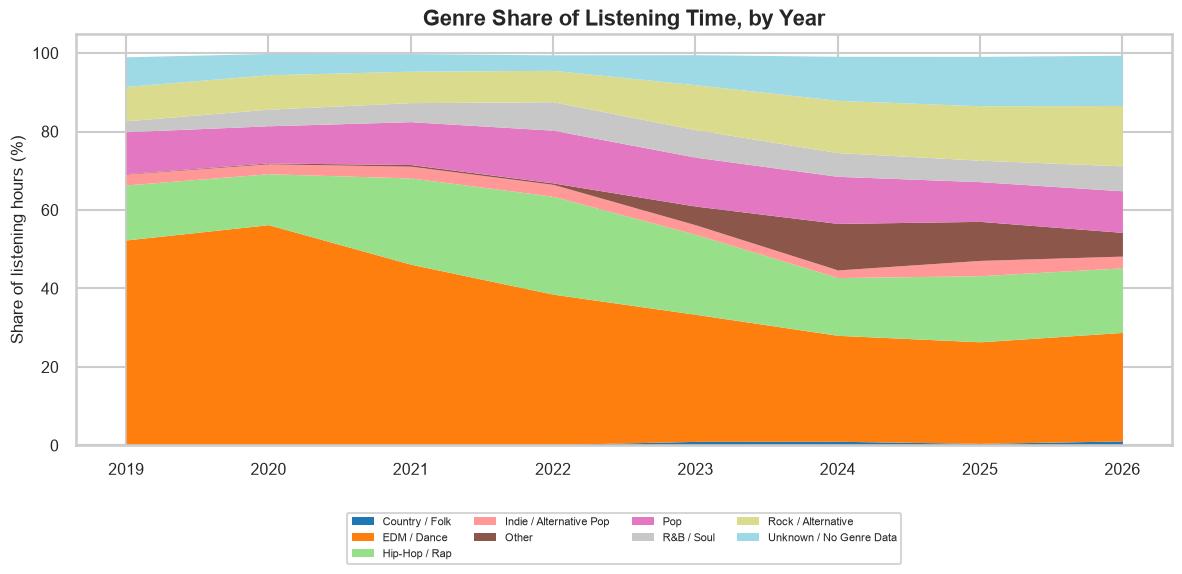

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
genre_share_by_year.plot.area(ax=ax, cmap="tab20", linewidth=0)
ax.set_title("Genre Share of Listening Time, by Year", fontsize=16, fontweight="bold")
ax.set_ylabel("Share of listening hours (%)")
ax.set_xlabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**EDM/Dance is the largest single bucket in every year of this
history** — not just on average, but in each individual year from 2019
through 2026. That's the first genuinely data-driven signal that EDM is
worth a closer, dedicated look later in this notebook (Section 8 picks
this up properly).

Beyond that headline: EDM's share has fallen substantially since its
2019-2020 peak, while Hip-Hop/Rap rose to a clear second place around
2021-2022 before settling back down, and Rock/Alternative has grown
slowly and steadily throughout.

### Cross-check

This project's existing pipeline already computed this same table
(`src/edm_analysis.py`, saved to `data/processed/genre_share_by_year.csv`)
and a lifetime EDM figure (`data/processed/edm_results.json`). Comparing
against both here.

In [6]:
existing_genre_csv = pd.read_csv(os.path.join(PROCESSED_DIR, "genre_share_by_year.csv"), index_col=0)
common_cols = [c for c in genre_share_by_year.columns if c in existing_genre_csv.columns]
diff = (genre_share_by_year[common_cols] - existing_genre_csv[common_cols]).abs()
print("Max abs. difference per genre bucket vs. existing genre_share_by_year.csv:")
print(diff.max())

lifetime_edm_hours = df_clean.loc[df_clean["is_edm"], "hours_played"].sum()
lifetime_total_hours = df_clean["hours_played"].sum()
lifetime_edm_share = lifetime_edm_hours / lifetime_total_hours

with open(os.path.join(PROCESSED_DIR, "edm_results.json")) as f:
    existing_edm_results = json.load(f)

print(f"\nLifetime EDM share -- notebook: {lifetime_edm_share:.4f} ({lifetime_edm_hours:.1f}h) "
      f"vs existing: {existing_edm_results['total_edm_hours_share_lifetime']} "
      f"({existing_edm_results['total_edm_hours']}h)")
match = abs(lifetime_edm_share - existing_edm_results["total_edm_hours_share_lifetime"]) < 0.001
print("MATCH" if match else "MISMATCH -- investigate")

Max abs. difference per genre bucket vs. existing genre_share_by_year.csv:
genre_bucket
Country / Folk             0.0
EDM / Dance                0.0
Hip-Hop / Rap              0.0
Indie / Alternative Pop    0.0
Other                      0.0
Pop                        0.0
R&B / Soul                 0.0
Rock / Alternative         0.0
Unknown / No Genre Data    0.0
dtype: float64



Lifetime EDM share -- notebook: 0.3657 (2705.4h) vs existing: 0.3657 (2705.4h)
MATCH


## 3. Artist trends over time

Lifetime favorites first, then a year-by-year view — because "who's on
top across the whole 7.5-year span" and "who was actually getting played
in any given year" can tell different stories.

In [7]:
top_artists_lifetime = (
    df_clean.groupby("artist_name")
    .agg(hours=("hours_played", "sum"), plays=("ms_played", "count"))
    .sort_values("hours", ascending=False)
    .round(1)
)
top_artists_lifetime.head(15)

,hours,plays
artist_name,,
Avicii,582.3,9858
Kanye West,370.6,6600
The Chainsmokers,226.0,4247
Kygo,184.9,3415
Jon Bellion,173.3,3463
Coldplay,144.6,2194
Maroon 5,119.3,2246
Calvin Harris,116.1,2212
One Direction,100.6,2057


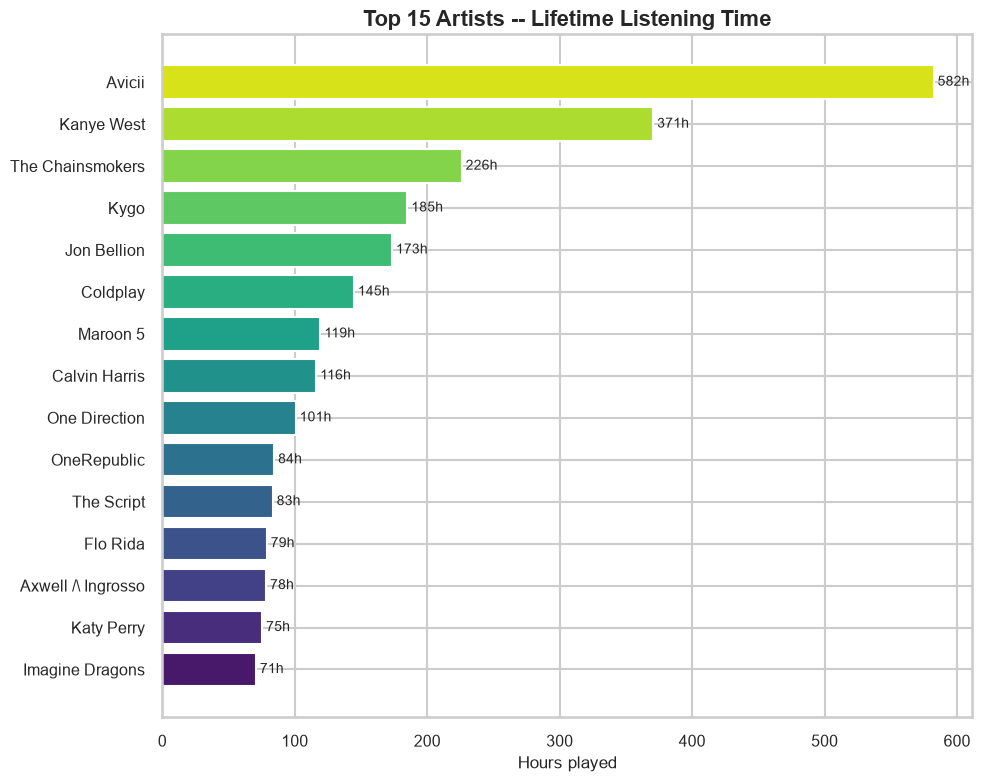

In [8]:
top15 = top_artists_lifetime.head(15).sort_values("hours")
fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(top15.index, top15["hours"], color=sns.color_palette(PALETTE, len(top15)))
ax.set_title("Top 15 Artists -- Lifetime Listening Time", fontsize=16, fontweight="bold")
ax.set_xlabel("Hours played")
for bar, hours in zip(bars, top15["hours"]):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2, f"{hours:.0f}h", va="center", fontsize=10)
fig.tight_layout()
plt.show()

In [9]:
top_artist_by_year = {}
for yr, grp in df_clean.groupby("year"):
    top5 = grp.groupby("artist_name")["hours_played"].sum().sort_values(ascending=False).head(5)
    top_artist_by_year[yr] = top5

print("Top artist (and runner-up) by year:")
for yr, s in top_artist_by_year.items():
    top2 = ", ".join(f"{name} ({hrs:.0f}h)" for name, hrs in s.head(2).items())
    print(f"  {yr}: {top2}")

Top artist (and runner-up) by year:
  2019: Avicii (96h), Jon Bellion (47h)
  2020: Avicii (118h), Kygo (36h)
  2021: Avicii (80h), The Chainsmokers (22h)
  2022: Kanye West (156h), Avicii (101h)
  2023: Kanye West (82h), Avicii (78h)
  2024: Avicii (59h), Kanye West (43h)
  2025: Kanye West (31h), Avicii (30h)
  2026: Kanye West (32h), Avicii (21h)


**Avicii holds the #1 spot for most of this history (2019-2021,
2024), but Kanye West overtakes as the leading artist in 2022, 2023, 2025,
and 2026** — the shift lines up with the broad listening spike identified
below, not a one-off. Favorites clearly rotate at the top over a span this
long, even though Avicii remains the runaway #1 lifetime.

### Cross-check

Comparing lifetime top artists and the top artist per year against
`data/processed/analysis_results.json` (`src/analysis.py`'s output).

In [10]:
with open(os.path.join(PROCESSED_DIR, "analysis_results.json")) as f:
    existing_analysis = json.load(f)

existing_top5 = pd.DataFrame(existing_analysis["top_lists"]["top_artists_lifetime"][:5]).set_index("artist_name")
mine_top5 = top_artists_lifetime.head(5)
print("Notebook top 5:\n", mine_top5)
print("\nExisting top 5:\n", existing_top5)

mismatches = []
for yr, s in top_artist_by_year.items():
    existing_top1 = existing_analysis["top_lists"]["top_artists_by_year"].get(str(yr), [{}])[0].get("artist_name")
    mine_top1 = s.index[0]
    if existing_top1 != mine_top1:
        mismatches.append((yr, mine_top1, existing_top1))
print("\nYear-by-year top-artist mismatches:", mismatches if mismatches else "none -- all years match")

Notebook top 5:
                   hours  plays
artist_name                   
Avicii            582.3   9858
Kanye West        370.6   6600
The Chainsmokers  226.0   4247
Kygo              184.9   3415
Jon Bellion       173.3   3463

Existing top 5:
                   hours  plays
artist_name                   
Avicii            582.3   9858
Kanye West        370.6   6600
The Chainsmokers  226.0   4247
Kygo              184.9   3415
Jon Bellion       173.3   3463

Year-by-year top-artist mismatches: none -- all years match


## 4. Time spent on songs / listening depth

*(New analysis -- this doesn't exist anywhere else in this project.)*

Everything above is about *which* artists and genres get played. This
section is about *how deeply* -- average play length, how concentrated
listening is at the track level (as opposed to the artist level already
covered), and how often a given track gets replayed versus played once
and never again.

In [11]:
avg_play_s = df_clean["ms_played"].mean() / 1000
median_play_s = df_clean["ms_played"].median() / 1000
print(f"Average play duration (30s+ plays only): {avg_play_s:.0f}s ({avg_play_s/60:.1f} min)")
print(f"Median play duration: {median_play_s:.0f}s ({median_play_s/60:.1f} min)")

Average play duration (30s+ plays only): 190s (3.2 min)
Median play duration: 200s (3.3 min)


### Track-level concentration

Section 3 showed the top 100 artists account for a large share of total
listening. Does the same concentration hold at the individual-track
level, or does listening spread out more once you're inside a favorite
artist's catalog?

One wrinkle worth flagging before the numbers: Spotify's export identifies
each track by a `track_uri` (its actual catalog ID), and a small but
real number of same-named tracks have *multiple* distinct URIs in this
history -- different album pressings, re-releases, or explicit/clean
variants logged separately even though a listener would think of them as
"the same song." Grouping by URI (the technically precise definition of
"a track") gives a different -- and lower -- concentration number than
grouping by the track's displayed name + artist. Both are shown below
rather than picking one silently.

In [12]:
by_uri = (
    df_clean.groupby("track_uri")
    .agg(hours=("hours_played", "sum"), name=("track_name", "first"), artist=("artist_name", "first"))
    .sort_values("hours", ascending=False)
)
by_label = (
    df_clean.assign(label=df_clean["track_name"] + " -- " + df_clean["artist_name"])
    .groupby("label")["hours_played"].sum()
    .sort_values(ascending=False)
)

total_hours = df_clean["hours_played"].sum()
print(f"{'N':>5} | {'share by track_uri':>20} | {'share by name+artist':>22}")
for n in (10, 50, 100):
    share_uri = by_uri["hours"].head(n).sum() / total_hours
    share_label = by_label.head(n).sum() / total_hours
    print(f"{n:>5} | {share_uri:>19.1%} | {share_label:>21.1%}")

print("\nFor comparison, the artist-level concentration curve (Section 3 / REPORT.md):")
print("  top 10 artists: 28.4%   top 50: 53.5%   top 100: 67.8%")
print("\n-> Track-level listening is far less concentrated than artist-level listening.")
print("   Favorite artists get replayed across many different songs, not obsessively on one track.")

    N |   share by track_uri |   share by name+artist
   10 |                7.2% |                  7.8%
   50 |               18.0% |                 19.4%
  100 |               25.6% |                 27.1%

For comparison, the artist-level concentration curve (Section 3 / REPORT.md):
  top 10 artists: 28.4%   top 50: 53.5%   top 100: 67.8%

-> Track-level listening is far less concentrated than artist-level listening.
   Favorite artists get replayed across many different songs, not obsessively on one track.


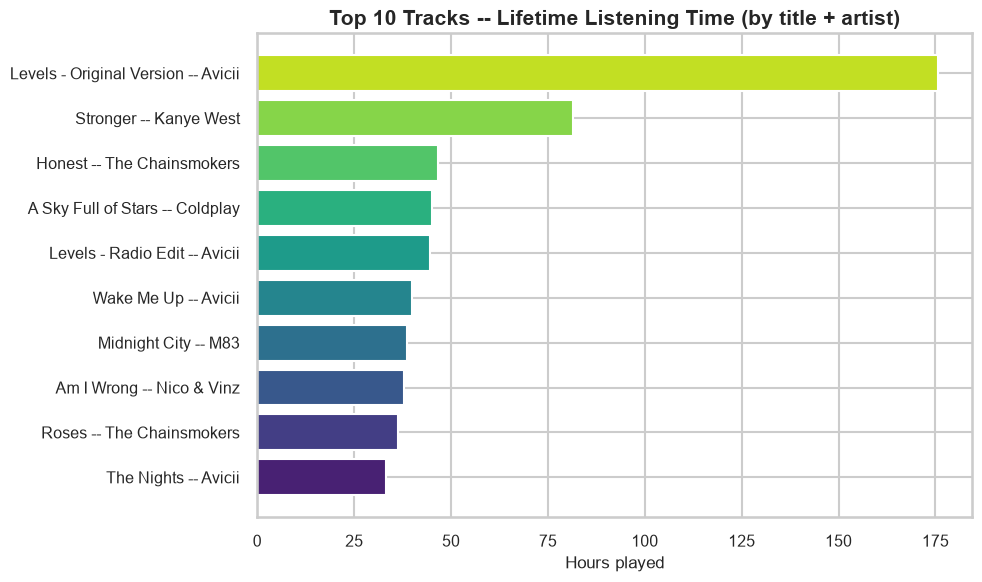


Note the #2 track by this grouping (title+artist) differs from grouping by the exact
Spotify track ID: 'Stronger -- Kanye West' totals 81.5h combined
across multiple distinct catalog entries, vs. 60.7h for the single largest one alone.


In [13]:
top10_display = by_label.head(10).round(1)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10_display.index[::-1], top10_display.values[::-1], color=sns.color_palette(PALETTE, 10))
ax.set_title("Top 10 Tracks -- Lifetime Listening Time (by title + artist)", fontsize=15, fontweight="bold")
ax.set_xlabel("Hours played")
fig.tight_layout()
plt.show()

print("\nNote the #2 track by this grouping (title+artist) differs from grouping by the exact")
print(f"Spotify track ID: 'Stronger -- Kanye West' totals {by_label.loc['Stronger -- Kanye West']:.1f}h combined")
print(f"across multiple distinct catalog entries, vs. {by_uri.iloc[1]['hours']:.1f}h for the single largest one alone.")

### Plays-per-track distribution

How many times does a typical track get played, and how many are one-off
plays that never get repeated?

In [14]:
plays_per_track = df_clean.groupby("track_uri").size()
once_only = (plays_per_track == 1).sum()

print(f"Mean plays per track:   {plays_per_track.mean():.2f}")
print(f"Median plays per track: {plays_per_track.median():.0f}")
print(f"Max plays (single track): {plays_per_track.max():,} -- {by_uri.iloc[0]['name']} by {by_uri.iloc[0]['artist']}")
print(f"Tracks played exactly once: {once_only:,} of {len(plays_per_track):,} ({once_only/len(plays_per_track):.1%})")

Mean plays per track:   14.22
Median plays per track: 2
Max plays (single track): 2,098 -- Levels - Original Version by Avicii
Tracks played exactly once: 4,869 of 9,859 (49.4%)


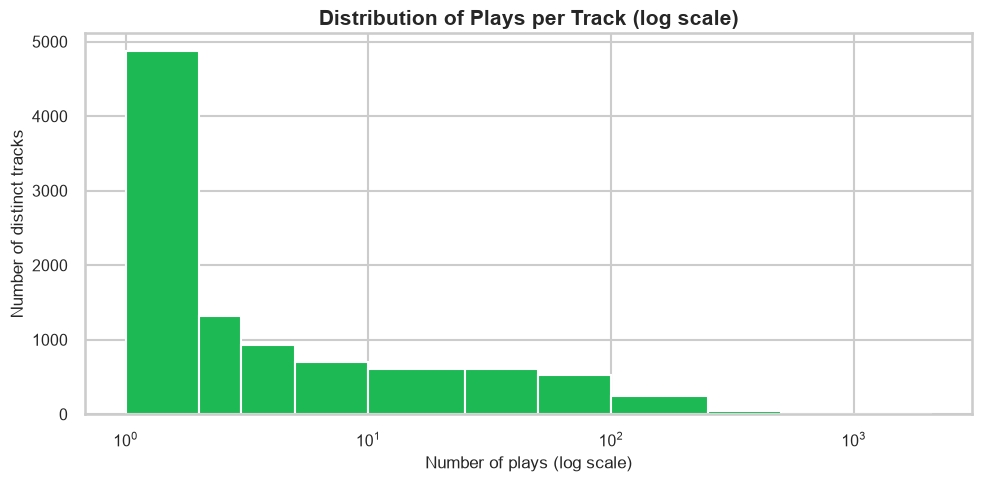

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = [1, 2, 3, 5, 10, 25, 50, 100, 250, 500, 1000, plays_per_track.max() + 1]
ax.hist(plays_per_track, bins=bins, color=ACCENT, edgecolor="white")
ax.set_xscale("log")
ax.set_title("Distribution of Plays per Track (log scale)", fontsize=15, fontweight="bold")
ax.set_xlabel("Number of plays (log scale)")
ax.set_ylabel("Number of distinct tracks")
fig.tight_layout()
plt.show()

**Nearly half of all distinct tracks (49.4%) in this history were
played exactly once.** That's a real, honest counterpoint to the
"repeat listener" framing from the habits section later on: repeat
listening is concentrated in a relatively small set of tracks played
often (median just 2 plays per track; a handful played 100s or 1,000s of
times), while a long tail of one-off plays makes up nearly half of the
total *catalog* even though it's a small share of total *hours*. Both
things are true about this listener at once.

## 5. Seasonality

*(New analysis.)* Everything about "when" so far has been either
calendar-year trends (does 2022 look different from 2021?) or
time-of-day/day-of-week patterns (covered in the habits section next).
This is a different question: **aggregated across every year, is there a
within-year seasonal pattern** -- more listening in certain months
regardless of which year it was?

In [16]:
df_clean["calendar_month_num"] = df_clean["ts_local"].dt.month
df_clean["calendar_month_name"] = df_clean["ts_local"].dt.month_name()

seasonal = (
    df_clean.groupby(["calendar_month_num", "calendar_month_name"])["hours_played"]
    .sum().reset_index().sort_values("calendar_month_num")
)
seasonal["share_pct"] = (seasonal["hours_played"] / seasonal["hours_played"].sum() * 100).round(2)
seasonal[["calendar_month_name", "hours_played", "share_pct"]].round(1)

,calendar_month_name,hours_played,share_pct
0,January,571.1,7.7
1,February,586.7,7.9
2,March,777.2,10.5
3,April,634.2,8.6
4,May,664.8,9.0
5,June,707.8,9.6
6,July,748.4,10.1
7,August,616.4,8.3
8,September,596.8,8.1
9,October,478.5,6.5


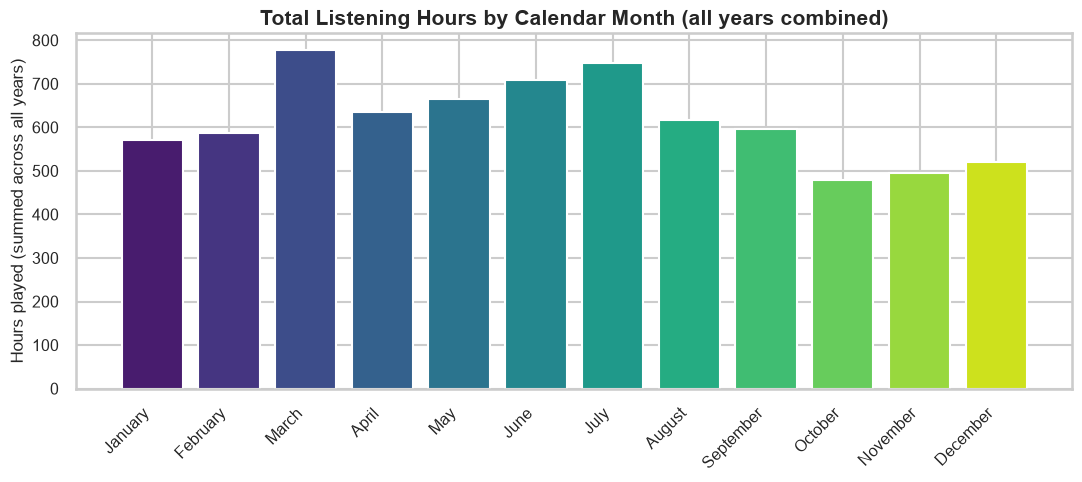

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(seasonal["calendar_month_name"], seasonal["hours_played"], color=sns.color_palette(PALETTE, 12))
ax.set_title("Total Listening Hours by Calendar Month (all years combined)", fontsize=15, fontweight="bold")
ax.set_ylabel("Hours played (summed across all years)")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
plt.show()

At face value, March and July stand out as the highest-volume
months, October and November the lowest -- but 2022 (this dataset's
outlier year, see Section 3 / the habits section) contained an especially
heavy March. Worth checking whether that one year is creating a seasonal
pattern that isn't really there.

In [18]:
seasonal_no_2022 = (
    df_clean[df_clean["year"] != 2022]
    .groupby("calendar_month_name")["hours_played"].sum()
    .reindex(seasonal.sort_values("calendar_month_num")["calendar_month_name"])
)
print("Hours by calendar month, 2022 EXCLUDED:")
print(seasonal_no_2022.round(1).sort_values(ascending=False))

ratio = seasonal_no_2022.max() / seasonal_no_2022.min()
print(f"\nHighest month / lowest month ratio (2022 excluded): {ratio:.2f}x")

Hours by calendar month, 2022 EXCLUDED:
calendar_month_name
July         602.2
June         564.0
March        563.8
May          483.4
August       455.1
January      445.7
April        444.3
February     440.3
September    439.7
December     408.5
November     351.4
October      311.7
Name: hours_played, dtype: float64

Highest month / lowest month ratio (2022 excluded): 1.93x


**The pattern holds even with 2022 removed** -- July, June, and
March remain the highest months, October and November remain the lowest,
with roughly a 2x gap between the busiest and quietest month. This is a
real, if modest, seasonal effect (summer-into-monsoon months higher,
autumn lower) rather than purely a 2022 artifact -- reported honestly at
the strength it actually shows, not stretched into a bigger story than a
~2x ratio supports.

## 6. Listening habits

Daily consistency, session structure, skip behavior, discovery vs.
repeat listening, and platform split. These already exist elsewhere in
this project (`data/processed/extended_stats.json` and
`analysis_results.json`) -- reproduced here from the underlying data with
real code, cross-checked against those files rather than just printing
them.

### Daily consistency

Using the **full, unfiltered** play data here (same reasoning as skip
behavior below): even a short/accidental play still means the app was
opened that day, which is what "consistency" is meant to capture --
filtering it out would remove exactly the signal of interest.

In [19]:
dates_with_play = pd.Series(sorted(pd.to_datetime(df_full["ts_local"].dt.date.unique())))
full_range = pd.date_range(dates_with_play.iloc[0], dates_with_play.iloc[-1], freq="D")

day_diffs = dates_with_play.diff().dt.days.fillna(1)
streak_id = (day_diffs != 1).cumsum()
streak_lengths = dates_with_play.groupby(streak_id).size()
longest_streak_dates = dates_with_play[streak_id == streak_lengths.idxmax()]

gaps = dates_with_play.diff().dt.days.dropna()
longest_gap_days = int(gaps.max() - 1)

print(f"Days with >=1 play: {len(dates_with_play):,} of {len(full_range):,} in range "
      f"({len(dates_with_play)/len(full_range):.1%})")
print(f"Longest consecutive-day streak: {streak_lengths.max()} days "
      f"({longest_streak_dates.iloc[0].date()} -> {longest_streak_dates.iloc[-1].date()})")
print(f"Longest gap with zero listening: {longest_gap_days} days")

with open(os.path.join(PROCESSED_DIR, "extended_stats.json")) as f:
    existing_extended = json.load(f)
ec = existing_extended["listening_consistency"]
print("\nCross-check vs extended_stats.json:")
print(f"  days_with_play: mine={len(dates_with_play)} vs existing={ec['days_with_at_least_one_play']}")
print(f"  longest_streak: mine={streak_lengths.max()} vs existing={ec['longest_consecutive_day_streak']}")
print(f"  longest_gap:    mine={longest_gap_days} vs existing={ec['longest_gap_days']}")

Days with >=1 play: 2,705 of 2,750 in range (98.4%)
Longest consecutive-day streak: 589 days (2021-05-07 -> 2022-12-16)
Longest gap with zero listening: 4 days

Cross-check vs extended_stats.json:
  days_with_play: mine=2705 vs existing=2705
  longest_streak: mine=589 vs existing=589
  longest_gap:    mine=4 vs existing=4


### Session-level listening

A session = a run of plays with no gap longer than 30 minutes between
consecutive tracks. Built from the **clean** dataset here, consistent
with how this project treats "real" listening everywhere except skip
behavior specifically.

In [20]:
gap_minutes = df_clean["ts"].diff().dt.total_seconds().div(60)
new_session = (gap_minutes.isna()) | (gap_minutes > 30)
df_clean["session_id"] = new_session.cumsum()

sessions = df_clean.groupby("session_id").agg(
    n_tracks=("track_name", "count"), hours=("hours_played", "sum"),
    start=("ts_local", "min"), end=("ts_local", "max"),
)
last_track_ms = df_clean.groupby("session_id")["ms_played"].last()
sessions["span_min"] = (
    (sessions["end"] - sessions["start"]).dt.total_seconds() / 60
    + last_track_ms.reindex(sessions.index).fillna(0) / 60_000
)

longest = sessions.loc[sessions["span_min"].idxmax()]
most_active_day = df_clean.groupby(df_clean["ts_local"].dt.date)["hours_played"].sum().sort_values(ascending=False)

print(f"Total sessions: {len(sessions):,}")
print(f"Median session: {sessions['n_tracks'].median():.0f} tracks, {sessions['span_min'].median():.1f} min")
print(f"Longest session: {longest['span_min']:.1f} min on {longest['start'].date()}, "
      f"{int(longest['n_tracks'])} tracks, {longest['hours']:.2f}h actually played")
print(f"Most active single day: {most_active_day.index[0]} at {most_active_day.iloc[0]:.2f}h")

es = existing_extended["session_stats"]
print("\nCross-check vs extended_stats.json:")
print(f"  total_sessions: mine={len(sessions)} vs existing={es['total_sessions']}")
print(f"  longest_session_span_min: mine={longest['span_min']:.1f} vs existing={es['longest_session']['span_minutes']}")
print(f"  most_active_day: mine={most_active_day.index[0]} ({most_active_day.iloc[0]:.2f}h) "
      f"vs existing={es['most_active_day']['date']} ({es['most_active_day']['hours']}h)")

Total sessions: 14,572
Median session: 6 tracks, 24.4 min
Longest session: 538.4 min on 2022-04-25, 112 tracks, 6.54h actually played
Most active single day: 2022-05-12 at 13.92h

Cross-check vs extended_stats.json:
  total_sessions: mine=14572 vs existing=14572
  longest_session_span_min: mine=538.4 vs existing=538.4
  most_active_day: mine=2022-05-12 (13.92h) vs existing=2022-05-12 (13.92h)


### Skip behavior

Two signals, using the **full** dataset (filtering would remove exactly
what's being measured here):

In [21]:
overall_skip_flag_rate = df_full["skipped"].mean()
cut_short_rate = (df_full["ms_played"] < 30_000).mean()
skip_by_year = df_full.groupby("year")["skipped"].mean()

print(f"Spotify's own 'skipped' flag: {overall_skip_flag_rate:.1%} overall")
print(f"Plays cut short under 30s:    {cut_short_rate:.1%} overall")
print("\nskip flag rate by year (note: flat 0% for 2019-2021 -- see methodology note below):")
print(skip_by_year.round(3))

print(f"\nCross-check vs analysis_results.json: "
      f"skip_flag={overall_skip_flag_rate:.3f} vs {existing_analysis['skip_behavior']['overall_skip_flag_rate']}, "
      f"cut_short={cut_short_rate:.3f} vs {existing_analysis['skip_behavior']['cut_short_under_30s_rate']}")

Spotify's own 'skipped' flag: 22.6% overall
Plays cut short under 30s:    40.7% overall

skip flag rate by year (note: flat 0% for 2019-2021 -- see methodology note below):
year
2019    0.000
2020    0.000
2021    0.000
2022    0.073
2023    0.442
2024    0.419
2025    0.544
2026    0.447
Name: skipped, dtype: float64

Cross-check vs analysis_results.json: skip_flag=0.226 vs 0.226, cut_short=0.407 vs 0.407


*(The `skipped` flag being exactly 0% for three straight years,
then jumping to 40-50%+, is almost certainly a data-collection artifact
in Spotify's own export -- not three years of never skipping a single
track. Treated as unreliable before 2022 throughout this project; the
30-second cutoff rate is the more trustworthy cross-era signal.)*

### Discovery vs. repeat listening

"Discovery" here means an artist's first-ever appearance in this whole
dataset falls in that year -- a lifetime-relative definition, not
"new in the last N months" relative to today.

In [22]:
first_seen_artist = df_clean.groupby("artist_name")["ts"].min()
df_clean["artist_first_year"] = df_clean["artist_name"].map(first_seen_artist).dt.tz_convert(LOCAL_TZ).dt.year
new_artist_share_by_year = (df_clean["artist_first_year"] == df_clean["year"]).groupby(df_clean["year"]).mean()

print("Share of plays each year that are of a newly-first-heard artist:")
print(new_artist_share_by_year.round(3))

existing_discovery = existing_analysis["discovery_vs_repeat"]["plays_that_are_new_artist_share_by_year"]
mismatch = {yr: (v, existing_discovery.get(str(yr))) for yr, v in new_artist_share_by_year.round(3).items()
            if abs(v - existing_discovery.get(str(yr), -1)) > 0.001}
print("\nMismatches vs analysis_results.json:", mismatch if mismatch else "none -- all years match")

Share of plays each year that are of a newly-first-heard artist:
year
2019    1.000
2020    0.157
2021    0.072
2022    0.033
2023    0.093
2024    0.048
2025    0.069
2026    0.052
dtype: float64

Mismatches vs analysis_results.json: none -- all years match


**90%+ of plays in most years are repeat listening to
already-known artists** -- consistent with the plays-per-track finding in
Section 4: this is a listener who returns to favorites far more than one
who's constantly finding new artists, even though (per Section 4) nearly
half the *distinct tracks* played only happened once.

### Platform split

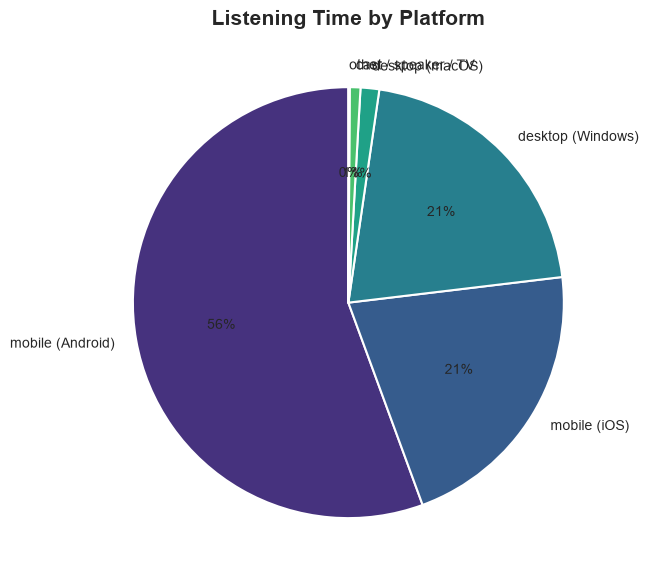


Cross-check vs analysis_results.json:
  mobile (Android): mine=4116.1 vs existing=4116.1
  mobile (iOS): mine=1576.9 vs existing=1576.9
  desktop (Windows): mine=1541.4 vs existing=1541.4
  desktop (macOS): mine=101.1 vs existing=101.1
  cast / speaker / TV: mine=59.1 vs existing=59.1
  other: mine=4.2 vs existing=4.2


In [23]:
platform_hours = df_clean.groupby("platform_group")["hours_played"].sum().sort_values(ascending=False)
platform_share = (platform_hours / platform_hours.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(platform_share.values, labels=platform_share.index, autopct="%1.0f%%",
       colors=sns.color_palette(PALETTE, len(platform_share)), startangle=90, textprops={"fontsize": 10})
ax.set_title("Listening Time by Platform", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

print("\nCross-check vs analysis_results.json:")
existing_platform = existing_analysis["platform_patterns"]["hours_by_platform"]
for plat, hrs in platform_hours.round(1).items():
    print(f"  {plat}: mine={hrs} vs existing={existing_platform.get(plat)}")

**Mobile listening (Android + iOS combined) accounts for ~77% of
all hours**, with Android alone over half -- consistent across every
cross-check above.

## 7. Why EDM, specifically

Section 2's genre-trends chart showed EDM/Dance as the largest single
genre bucket in **every year** of this dataset -- not picked in advance,
just what fell out of running the same bucketing logic used for every
other genre. That's the only reason for the deep dive below: the data
flagged it first.

## 8. EDM deep dive

### Top EDM artists and tracks

In [24]:
edm_df = df_clean[df_clean["is_edm"]].copy()
top_edm_artists = edm_df.groupby("artist_name")["hours_played"].sum().sort_values(ascending=False)
top_edm_artists.head(10).round(1)

artist_name
Avicii                582.3
The Chainsmokers      226.0
Kygo                  184.9
Calvin Harris         116.1
Flo Rida               78.8
Axwell /\ Ingrosso     78.3
Martin Garrix          70.0
Justin Bieber          66.3
David Guetta           52.2
Pitbull                51.1
Name: hours_played, dtype: float64

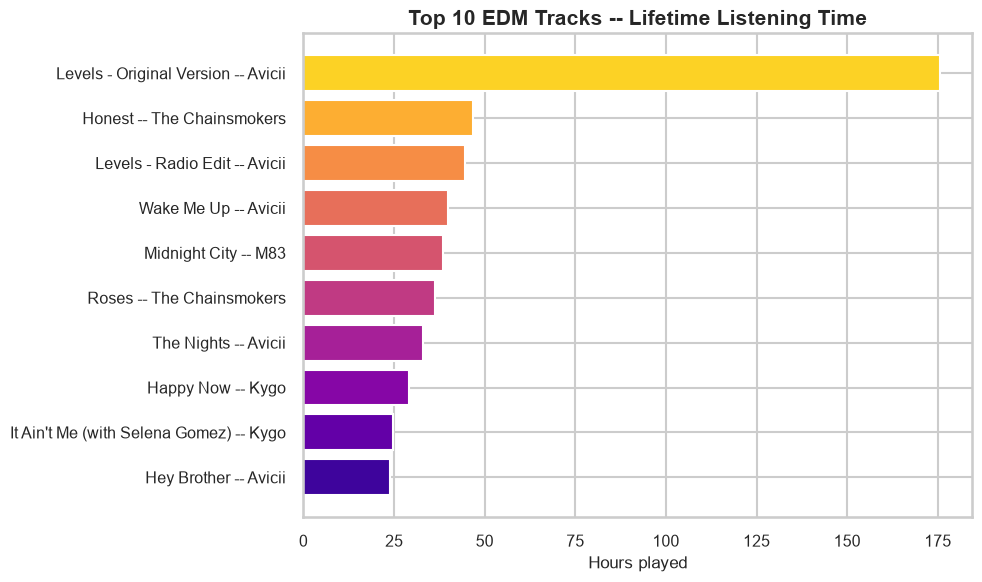

In [25]:
edm_by_label = (
    edm_df.assign(label=edm_df["track_name"] + " -- " + edm_df["artist_name"])
    .groupby("label")["hours_played"].sum().sort_values(ascending=False)
)
top10 = edm_by_label.head(10).round(1).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10.index, top10.values, color=sns.color_palette("plasma", len(top10)))
ax.set_title("Top 10 EDM Tracks -- Lifetime Listening Time", fontsize=15, fontweight="bold")
ax.set_xlabel("Hours played")
fig.tight_layout()
plt.show()

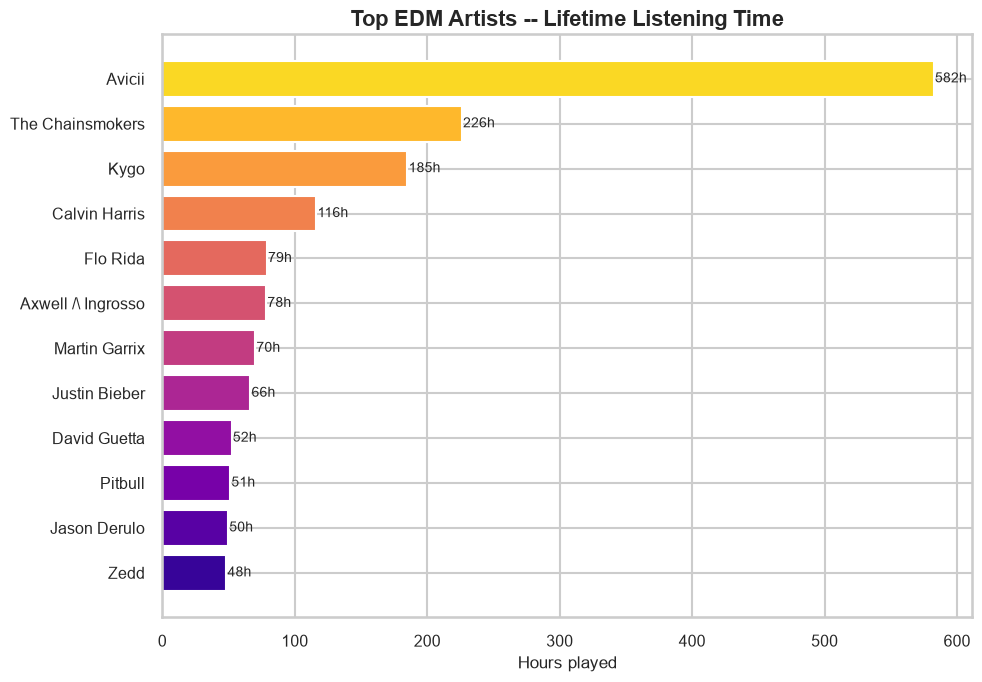

Cross-check vs edm_results.json top_edm_artists[:5]:
  Avicii: mine=582.3 vs existing=582.3
  The Chainsmokers: mine=226.0 vs existing=226.0
  Kygo: mine=184.9 vs existing=184.9
  Calvin Harris: mine=116.1 vs existing=116.1
  Flo Rida: mine=78.8 vs existing=78.8


In [26]:
top12 = top_edm_artists.head(12).round(1).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top12.index, top12.values, color=sns.color_palette("plasma", len(top12)))
ax.set_title("Top EDM Artists -- Lifetime Listening Time", fontsize=16, fontweight="bold")
ax.set_xlabel("Hours played")
for bar, hours in zip(bars, top12.values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{hours:.0f}h", va="center", fontsize=10)
fig.tight_layout()
plt.show()

print("Cross-check vs edm_results.json top_edm_artists[:5]:")
for r in existing_edm_results["top_edm_artists"][:5]:
    mine = round(top_edm_artists.get(r["artist_name"]), 1)
    print(f"  {r['artist_name']}: mine={mine} vs existing={r['hours']}")

### EDM sub-genre breakdown

Sub-genres aren't mutually exclusive here (an artist tagged both "house"
and "big room" counts toward both) -- this isn't a 100%-stacked view,
just which specific EDM styles show up and how much.

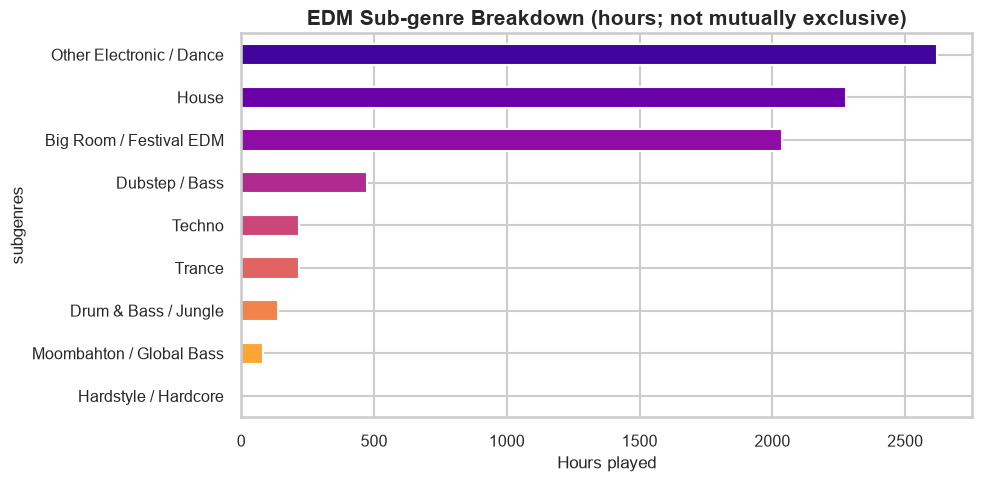

Cross-check vs edm_results.json edm_subgenre_hours:
  Other Electronic / Dance: mine=2621.3 vs existing=2621.3
  House: mine=2275.3 vs existing=2275.3
  Big Room / Festival EDM: mine=2036.1 vs existing=2036.1
  Dubstep / Bass: mine=471.8 vs existing=471.8
  Techno: mine=218.7 vs existing=218.7
  Trance: mine=215.5 vs existing=215.5
  Drum & Bass / Jungle: mine=138.6 vs existing=138.6
  Moombahton / Global Bass: mine=82.9 vs existing=82.9
  Hardstyle / Hardcore: mine=0.0 vs existing=0.0


In [27]:
EDM_SUBGENRE_KEYWORDS = [
    ("House", ["house"]),
    ("Techno", ["techno"]),
    ("Trance", ["trance"]),
    ("Dubstep / Bass", ["dubstep", "brostep", "riddim", "bass music", "future bass"]),
    ("Drum & Bass / Jungle", ["drum and bass", "dnb", "jungle", "breakbeat", "drumstep"]),
    ("Hardstyle / Hardcore", ["hardstyle", "hardcore techno", "gabber"]),
    ("Big Room / Festival EDM", ["big room", "edm", "electro house"]),
    ("Moombahton / Global Bass", ["moombahton"]),
    ("Other Electronic / Dance", ["electronica", "electro", "dance", "eurodance", "complextro"]),
]


def edm_subgenres(genres):
    lowered = [g.lower() for g in genres]
    return [sg for sg, kws in EDM_SUBGENRE_KEYWORDS if any(kw in g for kw in kws for g in lowered)]


edm_df["raw_genres"] = edm_df["artist_name"].map(genre_lookup)
edm_df["subgenres"] = edm_df["raw_genres"].map(edm_subgenres)
exploded = edm_df.explode("subgenres").dropna(subset=["subgenres"])
subgenre_hours = exploded.groupby("subgenres")["hours_played"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
subgenre_hours.round(1).plot.barh(ax=ax, color=sns.color_palette("plasma", len(subgenre_hours)))
ax.invert_yaxis()
ax.set_title("EDM Sub-genre Breakdown (hours; not mutually exclusive)", fontsize=15, fontweight="bold")
ax.set_xlabel("Hours played")
fig.tight_layout()
plt.show()

print("Cross-check vs edm_results.json edm_subgenre_hours:")
for sg, hrs in subgenre_hours.round(1).items():
    print(f"  {sg}: mine={hrs} vs existing={existing_edm_results['edm_subgenre_hours'].get(sg)}")

*(One honest caveat: "Other Electronic / Dance" is too broad to be a
meaningfully distinct sub-genre -- its keywords ("electro," "dance,"
"electronica") are substrings of most EDM tags, so it captures nearly all
EDM listening rather than a specific scene. Best read as "has some
generic electronic/dance tag," not a category alongside House or
Techno.)*

### EDM vs. overall listening patterns

Checking whether EDM listening looks different from overall listening on
three fronts: time of day, concentration among top artists, and skip
rate. Reported honestly either way -- two of these turn out to show a
real difference, one doesn't.

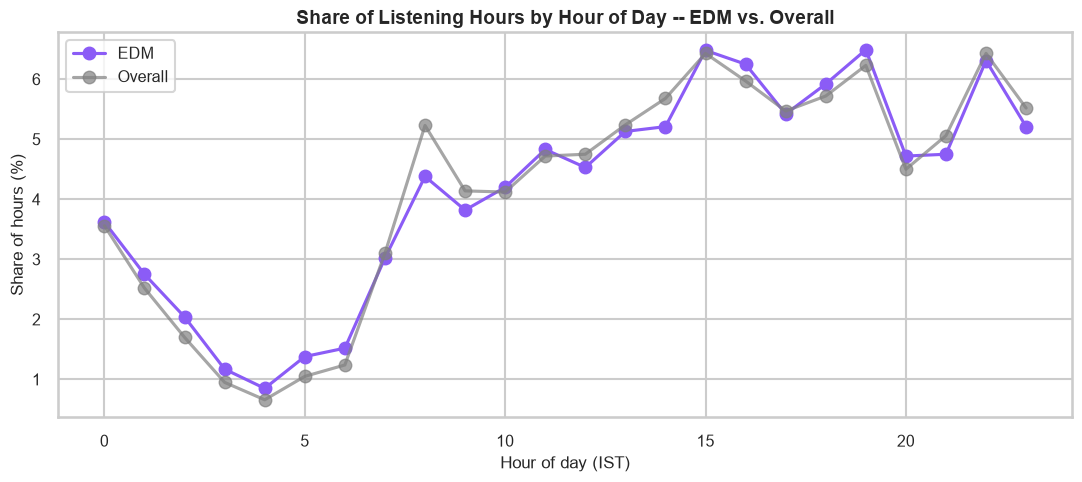

EDM's busiest hours: [19, 15, 22]
Overall busiest hours: [22, 15, 19]
-> No meaningful time-of-day skew: EDM follows essentially the same all-day pattern as everything else.


In [28]:
def normalized_dist(df, col):
    s = df.groupby(col)["hours_played"].sum()
    return (s / s.sum() * 100).round(2)

edm_by_hour = normalized_dist(edm_df, "hour")
overall_by_hour = normalized_dist(df_clean, "hour")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(edm_by_hour.index, edm_by_hour.values, marker="o", label="EDM", color="#8B5CF6")
ax.plot(overall_by_hour.index, overall_by_hour.values, marker="o", label="Overall", color="gray", alpha=0.7)
ax.set_title("Share of Listening Hours by Hour of Day -- EDM vs. Overall", fontsize=14, fontweight="bold")
ax.set_xlabel("Hour of day (IST)")
ax.set_ylabel("Share of hours (%)")
ax.legend()
fig.tight_layout()
plt.show()

print("EDM's busiest hours:", edm_by_hour.sort_values(ascending=False).head(3).index.tolist())
print("Overall busiest hours:", overall_by_hour.sort_values(ascending=False).head(3).index.tolist())
print("-> No meaningful time-of-day skew: EDM follows essentially the same all-day pattern as everything else.")

In [29]:
edm_top5_share = top_edm_artists.head(5).sum() / top_edm_artists.sum()
overall_top5_share = df_clean.groupby("artist_name")["hours_played"].sum().sort_values(ascending=False).head(5).sum() / total_hours

skip_by_bucket_full = df_full.copy()
skip_by_bucket_full["genre_bucket"] = skip_by_bucket_full["artist_name"].map(bucket_lookup).fillna("Unknown / No Genre Data")
edm_skip_rate = skip_by_bucket_full.loc[skip_by_bucket_full["genre_bucket"] == "EDM / Dance", "skipped"].mean()
overall_skip_rate = skip_by_bucket_full["skipped"].mean()

print(f"Concentration -- top 5 EDM artists: {edm_top5_share:.1%} of EDM hours "
      f"vs top 5 overall artists: {overall_top5_share:.1%} of all hours")
print(f"  -> EDM listening is MORE concentrated in a handful of favorites than overall listening.")
print(f"\nSkip rate -- EDM: {edm_skip_rate:.1%} vs overall: {overall_skip_rate:.1%}")
print(f"  -> EDM has a meaningfully LOWER skip rate than the overall average.")

print("\nCross-check vs edm_results.json:")
print(f"  concentration: mine edm_top5={edm_top5_share:.3f} vs existing={existing_edm_results['concentration']['edm_top5_artist_share_of_edm_hours']}")
edm_skip_existing = [r for r in existing_edm_results["skip_rate_by_genre_bucket"] if r["genre_bucket"] == "EDM / Dance"][0]
print(f"  skip_rate: mine={edm_skip_rate:.3f} vs existing={edm_skip_existing['skip_rate']}")

Concentration -- top 5 EDM artists: 43.9% of EDM hours vs top 5 overall artists: 20.8% of all hours
  -> EDM listening is MORE concentrated in a handful of favorites than overall listening.

Skip rate -- EDM: 16.7% vs overall: 22.6%
  -> EDM has a meaningfully LOWER skip rate than the overall average.

Cross-check vs edm_results.json:
  concentration: mine edm_top5=0.439 vs existing=0.439
  skip_rate: mine=0.167 vs existing=0.167


### Genre-coverage tail check

Is EDM listening hiding disproportionately in the artists this project's
genre-resolution pipeline never got to? This specific check needed live
MusicBrainz calls -- it works by pulling a random sample of
*then-currently-unresolved* artists and resolving them on the spot to see
if EDM shows up more or less often than in the already-covered set. That
can't be reproduced in a notebook that makes no network calls, so the
precomputed result from when this check was actually run
(`src/edm_tail_coverage_check.py`, `data/processed/edm_tail_coverage_check.json`)
is loaded and shown as-is below, rather than faking a live recomputation.

In [30]:
with open(os.path.join(PROCESSED_DIR, "edm_tail_coverage_check.json")) as f:
    tail_check = json.load(f)

print(f"Covered-set EDM share:  {tail_check['covered_edm_share']:.1%} "
      f"({tail_check['covered_edm_count']}/{tail_check['covered_set_size']} artists)")
print(f"Tail-sample EDM share:  {tail_check['sample_edm_share']:.1%} "
      f"({tail_check['sample_edm_count']}/{tail_check['sample_size']} artists, "
      f"random seed={tail_check['random_seed']})")
print("\n-> The unresolved tail is LESS EDM-dense than the covered set, not more -- "
      "this rules out EDM hiding disproportionately in unresolved artists.")
print("   (Precomputed result, loaded as-is -- not regenerated in this notebook. See note above.)")

Covered-set EDM share:  32.9% (249/758 artists)
Tail-sample EDM share:  15.8% (12/76 artists, random seed=42)

-> The unresolved tail is LESS EDM-dense than the covered set, not more -- this rules out EDM hiding disproportionately in unresolved artists.
   (Precomputed result, loaded as-is -- not regenerated in this notebook. See note above.)


## 9. Methodology notes

A few real build-time issues worth a brief mention -- not the focus of
this notebook, but part of the honest story of how this analysis came
together. Full detail is in this project's `README.md` if any of these
are of interest.

**The Spotify-to-MusicBrainz pivot.** Genre resolution originally targeted
Spotify's own Web API. Two independent problems killed that plan: a
sustained rate-limit wall that never cleared even after a genuine 24+
hour wait, and -- more seriously -- every artist that *did* resolve
before hitting that wall came back with an **empty** genre list,
including acts that are always heavily tagged on Spotify normally
(*NSYNC, 21 Savage). Checking the Spotify Developer Dashboard confirmed
the app was stuck in "Development mode," Spotify's most restricted access
tier -- explaining both symptoms at once, and meaning no amount of
patience would have fixed it. Genre resolution was rebuilt from scratch
around MusicBrainz: open, no API key, and a documented (if slow, ~1
request/second) rate limit instead of an opaque one.

**The Kanye West tag-bucketing bug.** Covered above in the genre-bucketing
section, but worth restating: MusicBrainz's tag data is a community
folksonomy, not a curated list, and a simple "any matching tag wins" rule
let a couple of stray "house" tags classify Kanye West -- 370.6 lifetime
hours, the #2 artist in this entire dataset -- as EDM, ahead of his 10+
genuine hip-hop/rap tags. Caught by checking *why* a specific high-impact
artist landed where it did, not just trusting the aggregate genre-share
numbers. Fixed with the plurality-vote rule used throughout this
notebook.

**The release-year idea, tried and dropped.** A natural sixth question --
does listening skew toward music released close to when it was played,
or toward older catalog material -- would have needed each track's
original release year, resolvable via MusicBrainz the same way artist
genres were. Testing this before building it revealed a real reliability
problem, not just a coverage gap: a single track/artist pair routinely
returns many MusicBrainz recording entries -- different mixes, remasters,
reissues -- tied at the *maximum* possible search-relevance score, with
release dates spanning a decade or more apart. A plain top-result search
for "Levels" by Avicii returned a date six years off from its real 2011
release. There's no reliable way to pick the true original release among
tied candidates from title-based search alone, so this was reported as a
genuine limitation rather than forced into a weak, misleading version of
the analysis.

## 10. What's next

This notebook -- along with the rest of this project's pipeline in
`src/`, and the `REPORT.md`/`README.md` write-up -- is the finished
Python phase of this project. The next phase is a **Tableau dashboard**,
built separately from a tidy, row-per-play export
(`data/tableau_export.csv`) already produced for exactly that purpose,
with every column's meaning documented in `README.md`.

The goal there is the same as it's been throughout this notebook: take
what's already been found here -- genre trends, the EDM story, listening
habits, the newer depth and seasonality findings -- and make it something
that can be explored interactively, not just read.